# Archived: early work-in-progress version

Kept for reference; the final experiments are in `../numin_meta_sgd.ipynb`. This version used a
Pearson-correlation inner loss, a cross-sectionally demeaned Sharpe objective with a smaller
training transaction cost (`0.001`), and the Absolute allocator with `top_k=4` and an inertia
bonus of 1.0. Its saved output (bottom of the notebook) shows the run's 10-epoch training log and
an out-of-sample backtest of 1,489 days with total profit 17.3244 and Sharpe 0.1875.

In [17]:
import math
import time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.func import functional_call
from torch.utils.data import Dataset, DataLoader
from numin2 import Numin2API

In [18]:
pd.set_option('io.parquet.engine', 'fastparquet')
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

In [19]:
class NuminAdvancedDataset(Dataset):
    def __init__(self, ohlcv_path, returns_path, seq_len=252):
        print(f"[DATA] Compiling temporal sequences (seq_len={seq_len})...")
        df_ohlcv = pd.read_parquet(ohlcv_path)
        df_returns = pd.read_parquet(returns_path)
        
        if isinstance(df_ohlcv.columns, pd.MultiIndex):
            df_ohlcv = df_ohlcv.stack(level=1, future_stack=True).reset_index()
            df_ohlcv.rename(columns={df_ohlcv.columns[0]: 'date', df_ohlcv.columns[1]: 'asset'}, inplace=True)
        elif isinstance(df_ohlcv.index, pd.MultiIndex):
            df_ohlcv = df_ohlcv.reset_index()
            
        if not isinstance(df_returns.columns, pd.MultiIndex) and 'asset' not in [str(c).lower() for c in df_returns.columns]:
            df_returns.index.name = 'date'
            df_returns = df_returns.reset_index().melt(id_vars=['date'], var_name='asset', value_name='returns')
        elif isinstance(df_returns.index, pd.MultiIndex):
            df_returns = df_returns.reset_index()

        df_ohlcv.columns = [str(c).lower() for c in df_ohlcv.columns]
        df_returns.columns = [str(c).lower() for c in df_returns.columns]
        
        if 'returns' in df_ohlcv.columns and 'returns' in df_returns.columns:
            df_ohlcv.drop(columns=['returns'], inplace=True)
            
        df_merged = pd.merge(df_ohlcv, df_returns, on=['date', 'asset'], how='inner')
        df_merged.sort_values(by=['date', 'asset'], inplace=True)
        
        self.dates = df_merged['date'].unique()
        self.num_assets = len(df_merged['asset'].unique()) 
        
        feature_cols = ['open', 'high', 'low', 'close', 'volume', 'returns']
        self.data = np.zeros((len(self.dates), self.num_assets, 6))
        
        for i, f in enumerate(feature_cols):
            if f in df_merged.columns:
                pivot_df = df_merged.pivot(index='date', columns='asset', values=f).fillna(0)
                self.data[:, :, i] = pivot_df.values
                
        self.data = torch.FloatTensor(self.data)
        self.seq_len = seq_len
        print(f"[DATA] Compilation complete. Tensor shape: {self.data.shape}")

    def __len__(self):
        return len(self.dates) - self.seq_len

    def __getitem__(self, idx):
        X = self.data[idx : idx + self.seq_len]
        y = self.data[idx + self.seq_len, :, 5] 
        return X, y

In [20]:
def get_custom_dataloaders(ohlcv_path, returns_path, batch_size=128):
    full_dataset = NuminAdvancedDataset(ohlcv_path, returns_path)
    train_size = int(0.7 * len(full_dataset))
    val_size = int(0.15 * len(full_dataset))
    
    train_dataset = torch.utils.data.Subset(full_dataset, range(0, train_size))
    val_dataset = torch.utils.data.Subset(full_dataset, range(train_size, train_size + val_size))
    test_dataset = torch.utils.data.Subset(full_dataset, range(train_size + val_size, len(full_dataset)))
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader

In [21]:
class AdvancedQuantFeatureBlock(nn.Module):
    def __init__(self, num_assets=50):
        super(AdvancedQuantFeatureBlock, self).__init__()
        self.num_assets = num_assets
        self.out_features = num_assets * 5

    def forward(self, x):
        B, T, N, F_dim = x.shape
        O, H, L, C = x[..., 0], x[..., 1], x[..., 2], x[..., 3]
        V, R = x[..., 4], x[..., 5]
        
        def cs_zscore(tensor):
            mean = tensor.mean(dim=-1, keepdim=True)
            std = tensor.std(dim=-1, keepdim=True) + 1e-6
            return (tensor - mean) / std

        log_hl = torch.log(H / (L + 1e-6) + 1e-6)
        log_co = torch.log(C / (O + 1e-6) + 1e-6)
        gk_internal = 0.5 * log_hl**2 - (2 * math.log(2) - 1) * log_co**2
        gk_vol = torch.sqrt(torch.clamp(gk_internal, min=1e-8))
        gk_vol_z = cs_zscore(gk_vol).unsqueeze(-1)
        
        cumsum_v = torch.cumsum(V, dim=1)
        sma_v = torch.zeros_like(V)
        sma_v[:, :20, :] = cumsum_v[:, :20, :] / torch.arange(1, min(T, 20)+1, device=x.device).view(1, -1, 1)
        if T > 20:
            sma_v[:, 20:, :] = (cumsum_v[:, 20:, :] - cumsum_v[:, :-20, :]) / 20.0
        rel_vol = V / (sma_v + 1e-6)
        rel_vol_z = cs_zscore(rel_vol).unsqueeze(-1)
        
        r_z = cs_zscore(R).unsqueeze(-1)
        
        cumsum_r = torch.cumsum(R, dim=1)
        mom_60d = torch.zeros_like(R)
        mom_60d[:, :60, :] = cumsum_r[:, :60, :]
        if T > 60:
            mom_60d[:, 60:, :] = cumsum_r[:, 60:, :] - cumsum_r[:, :-60, :]
        mom_60d_z = cs_zscore(mom_60d).unsqueeze(-1)
        
        out = torch.cat([R.unsqueeze(-1), gk_vol_z, rel_vol_z, r_z, mom_60d_z], dim=-1)
        return torch.nan_to_num(out.view(B, T, -1), nan=0.0)

In [22]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.4, max_len=500):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)

In [23]:
class MetaSGDTransformer(nn.Module):
    def __init__(self, num_assets=50, d_model=256, nhead=8, num_layers=4, dropout=0.3):
        super(MetaSGDTransformer, self).__init__()
        self.feature_block = AdvancedQuantFeatureBlock(num_assets=num_assets)
        self.input_projection = nn.Linear(self.feature_block.out_features, d_model)
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        
        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4, 
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layers, num_layers=num_layers)
        
        self.output_projection = nn.Sequential(
            nn.Linear(d_model, 128), nn.LayerNorm(128), nn.GELU(), 
            nn.Dropout(dropout), nn.Linear(128, num_assets)
        )
        
        self.inner_lrs = nn.ParameterDict({
            name.replace('.', '_'): nn.Parameter(torch.ones_like(param) * 0.005)
            for name, param in self.named_parameters() if param.requires_grad
        })

    def forward(self, x):
        x = self.feature_block(x)
        x = self.input_projection(x)
        x = self.pos_encoder(x)
        encoded = self.transformer(x)
        raw_alpha = self.output_projection(encoded[:, -1, :])
        return torch.tanh(raw_alpha)

In [24]:
class SAM(torch.optim.Optimizer):
    def __init__(self, params, base_optimizer, rho=0.05, adaptive=False, **kwargs):
        defaults = dict(rho=rho, adaptive=adaptive, **kwargs)
        super(SAM, self).__init__(params, defaults)
        self.base_optimizer = base_optimizer(self.param_groups, **kwargs)
        self.param_groups = self.base_optimizer.param_groups
        self.defaults.update(self.base_optimizer.defaults)

    @torch.no_grad()
    def first_step(self, zero_grad=False):
        grad_norm = self._grad_norm()
        for group in self.param_groups:
            scale = group["rho"] / (grad_norm + 1e-12)
            for p in group["params"]:
                if p.grad is None: continue
                self.state[p]["old_p"] = p.data.clone()
                e_w = (torch.pow(p, 2) if group["adaptive"] else 1.0) * p.grad * scale.to(p)
                p.add_(e_w)
        if zero_grad: self.zero_grad()

    @torch.no_grad()
    def second_step(self, zero_grad=False):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None: continue
                p.data = self.state[p]["old_p"]  
        self.base_optimizer.step()  
        if zero_grad: self.zero_grad()

    @torch.no_grad()
    def _grad_norm(self):
        shared_device = self.param_groups[0]["params"][0].device
        norm = torch.norm(
            torch.stack([
                ((torch.abs(p) if group["adaptive"] else 1.0) * p.grad).norm(p=2).to(shared_device)
                for group in self.param_groups for p in group["params"]
                if p.grad is not None
            ]),
            p=2
        )
        return norm

In [25]:
def differentiable_sharpe_loss(predictions, targets, txn_cost=0.001):
    portfolio_returns = (predictions * targets).sum(dim=1) 
    cash_start = torch.zeros(1, predictions.size(1), device=predictions.device)
    prev_predictions = torch.cat([cash_start, predictions[:-1]], dim=0)
    
    turnover = torch.abs(predictions - prev_predictions).sum(dim=1)
    net_returns = portfolio_returns - (txn_cost * turnover)
    
    mean_return = net_returns.mean()
    std_return = net_returns.std() + 1e-6 
    return -((mean_return / std_return) * math.sqrt(252))

In [26]:
def pearson_correlation_loss(preds, targets):
    preds_mean = preds.mean(dim=-1, keepdim=True)
    targets_mean = targets.mean(dim=-1, keepdim=True)
    
    preds_centered = preds - preds_mean
    targets_centered = targets - targets_mean
    
    cov = (preds_centered * targets_centered).sum(dim=-1)
    pred_var = (preds_centered ** 2).sum(dim=-1)
    target_var = (targets_centered ** 2).sum(dim=-1)
    
    corr = cov / torch.sqrt(pred_var * target_var + 1e-8)
    return -corr.mean()

In [27]:
def allocate_portfolio_absolute(continuous_signals, prev_weights=None, top_k=4, enter_threshold=0.6, inertia_bonus=1.0):
    batch_size = continuous_signals.shape[0]
    num_assets = continuous_signals.shape[1]
    weights = torch.zeros_like(continuous_signals)
    
    if prev_weights is None:
        prev_weights = torch.zeros(num_assets, device=continuous_signals.device)
        
    for i in range(batch_size):
        alphas = continuous_signals[i]
        adjusted_alphas = alphas + (prev_weights * inertia_bonus)
        
        abs_alphas = torch.abs(adjusted_alphas)
        _, top_idx = torch.topk(abs_alphas, top_k)
        
        current_w = torch.zeros(num_assets, device=continuous_signals.device)
        
        for idx in top_idx:
            if adjusted_alphas[idx] > enter_threshold:
                current_w[idx] = 1.0
            elif adjusted_alphas[idx] < -enter_threshold:
                current_w[idx] = -1.0

        weights[i] = current_w
        prev_weights = current_w 

    active_exposure = torch.abs(weights).sum(dim=1, keepdim=True)
    cash_column = torch.where(active_exposure == 0, 1.0, 0.0)
    
    return torch.cat((cash_column, weights), dim=1), prev_weights

In [28]:
def train_meta_sgd_sam(model, train_loader, meta_epochs=10, meta_lr=0.0003):
    print("\n" + "="*60)
    print(f"[{time.strftime('%X')}] PHASE 1: META-TRAINING INITIATED")
    print("="*60)
    
    base_optimizer = torch.optim.AdamW
    meta_optimizer = SAM(model.parameters(), base_optimizer, lr=meta_lr, weight_decay=1e-4, rho=0.05)
    inner_criterion = pearson_correlation_loss
    
    model.train()
    for epoch in range(meta_epochs):
        start_time = time.time()
        epoch_loss = 0.0
        batches = list(train_loader)
        
        for i in range(0, len(batches) - 1, 2):
            X_adapt, y_adapt = batches[i][0].to(device), batches[i][1].to(device)
            X_eval, y_eval = batches[i+1][0].to(device), batches[i+1][1].to(device)
            
            y_adapt = torch.nan_to_num(y_adapt, nan=0.0)
            y_eval = torch.nan_to_num(y_eval, nan=0.0)
            
            preds = model(X_adapt)
            inner_loss = inner_criterion(preds, y_adapt)
            grads = torch.autograd.grad(inner_loss, model.parameters(), create_graph=True, allow_unused=True)
            
            adapted_weights = {}
            for (name, param), grad in zip(model.named_parameters(), grads):
                if grad is None:
                    adapted_weights[name] = param
                else:
                    clean_name = name.replace('.', '_')
                    adapted_weights[name] = param - (model.inner_lrs[clean_name] * grad)
            
            meta_optimizer.zero_grad()
            
            eval_preds = functional_call(model, adapted_weights, X_eval) 
            eval_preds_neutral = eval_preds - eval_preds.mean(dim=-1, keepdim=True)
            meta_loss = differentiable_sharpe_loss(eval_preds_neutral, y_eval, txn_cost=0.001)
            
            meta_loss.backward() 
            meta_optimizer.first_step(zero_grad=True)
            
            preds_adv = model(X_adapt)
            inner_loss_adv = inner_criterion(preds_adv, y_adapt)
            grads_adv = torch.autograd.grad(inner_loss_adv, model.parameters(), create_graph=True, allow_unused=True)
            
            adapted_weights_adv = {}
            for (name, param), grad in zip(model.named_parameters(), grads_adv):
                if grad is None:
                    adapted_weights_adv[name] = param
                else:
                    clean_name = name.replace('.', '_')
                    adapted_weights_adv[name] = param - (model.inner_lrs[clean_name] * grad)
            
            eval_preds_perturbed = functional_call(model, adapted_weights_adv, X_eval)
            eval_preds_perturbed_neutral = eval_preds_perturbed - eval_preds_perturbed.mean(dim=-1, keepdim=True)
            meta_loss_perturbed = differentiable_sharpe_loss(eval_preds_perturbed_neutral, y_eval, txn_cost=0.001)
            
            meta_loss_perturbed.backward()
            meta_optimizer.second_step(zero_grad=True)
            
            epoch_loss += meta_loss_perturbed.item()
            
        num_task_batches = len(batches) // 2
        avg_loss = (epoch_loss / num_task_batches) if num_task_batches > 0 else 0.0
        elapsed = time.time() - start_time
        print(f"  [Epoch {epoch+1:02d}/{meta_epochs}] Worst-Case Sharpe Loss: {avg_loss:>7.4f} | Time: {elapsed:>5.1f}s")
        
    return model

In [29]:
def plot_equity_curve(results, save_path="equity_curve_wip.png"):
    daily_pnl = results.get('incremental_pnl', [])
    if not daily_pnl:
        return
    
   
    cumulative_pnl = np.cumsum(daily_pnl)
    
    plt.figure(figsize=(10, 5))
    plt.plot(cumulative_pnl, color='#2ca02c', linewidth=2, label='Meta-Learner (StatArb)')
    
  
    plt.fill_between(range(len(cumulative_pnl)), cumulative_pnl, color='#2ca02c', alpha=0.1)

    plt.title('Out-of-Sample Equity Curve (WIP)', fontsize=14, fontweight='bold')
    plt.xlabel('Trading Days (Out-of-Sample)', fontsize=12)
    plt.ylabel('Cumulative Profit (10bps Fee Included)', fontsize=12)
    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left', fontsize=12)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    print(f"\n[VISUALIZATION] Equity curve saved to {save_path}")

In [30]:
import matplotlib.pyplot as plt
def execute_advanced_strategy(ohlcv_path, returns_path):
    print("\n" + "="*60)
    print(f"[{time.strftime('%X')}] INITIALIZING META-LEARNING ARBITRAGE ENGINE")
    print("="*60)
    
    torch.backends.cuda.enable_flash_sdp(False)
    torch.backends.cuda.enable_mem_efficient_sdp(False)
    torch.backends.cuda.enable_math_sdp(True)
    
    client = Numin2API()
    
    train_loader, val_loader, test_loader = get_custom_dataloaders(ohlcv_path, returns_path, batch_size=128)
    
    model = MetaSGDTransformer(
        num_assets=50, 
        d_model=256, 
        nhead=8, 
        num_layers=4, 
        dropout=0.3
    ).to(device)
    
    model = train_meta_sgd_sam(model, train_loader, meta_epochs=10, meta_lr=0.0003)
    
    print("\n" + "="*60)
    print(f"[{time.strftime('%X')}] PHASE 2: OUT-OF-SAMPLE INFERENCE (ONLINE ADAPTATION)")
    print("="*60)
    
    all_test_positions = []
    all_test_targets = []
    current_portfolio_state = None 
    
    X_prev, y_prev = None, None
    inner_criterion = nn.MSELoss()
    
    total_batches = len(test_loader)
    print(f"[INFERENCE] Processing {total_batches} temporal blocks...")
    
    for batch_idx, (X_batch, y_batch) in enumerate(test_loader):
        X_batch = X_batch.to(device)
        clean_y_batch = torch.nan_to_num(y_batch, nan=0.0).to(device)
        
        if X_prev is not None:
            model.train() 
            preds_prev = model(X_prev)
            loss_prev = inner_criterion(preds_prev, y_prev)
            
            grads = torch.autograd.grad(loss_prev, model.parameters(), retain_graph=False, allow_unused=True)
            
            adapted_weights = {}
            for (name, param), grad in zip(model.named_parameters(), grads):
                if grad is None:
                    adapted_weights[name] = param
                else:
                    clean_name = name.replace('.', '_')
                    adapted_weights[name] = param - (model.inner_lrs[clean_name] * grad)
        else:
            adapted_weights = {name: param for name, param in model.named_parameters()}
            
        with torch.no_grad():
            model.eval() 
            continuous_predictions = functional_call(model, adapted_weights, X_batch)
            
            discrete_batch_positions, current_portfolio_state = allocate_portfolio_absolute(
                continuous_predictions, 
                prev_weights=current_portfolio_state,
                top_k=4,             
                enter_threshold=0.6,
                inertia_bonus=1.0    
            )
            
        nan_mask = torch.isnan(y_batch).to(device)
        discrete_batch_positions[:, 1:][nan_mask] = 0.0 
        clean_y_batch = torch.nan_to_num(y_batch, nan=0.0).to(device)
        
        all_test_positions.append(discrete_batch_positions.cpu())
        all_test_targets.append(clean_y_batch.cpu())
        
        X_prev = X_batch
        y_prev = clean_y_batch
        
    full_test_positions = torch.cat(all_test_positions, dim=0)
    full_test_targets = torch.cat(all_test_targets, dim=0)
    
    print("\n" + "="*60)
    print(f"[{time.strftime('%X')}] PHASE 3: EXECUTION & BACKTESTING")
    print("="*60)
    print(f"[EXECUTION] Submitting {full_test_positions.shape[0]} trading days to Numin2 Backtester...")
    print(f"[EXECUTION] Constraint: 10bps Transaction Fee (0.1)")
    
    results = client.backtest_positions(
        positions=full_test_positions.numpy(), 
        targets=full_test_targets.numpy(), 
        txn_cost=0.1  
    )
    
    print("\n[RESULTS] FINAL METRICS:")
    print("-" * 30)
    print(f"Total Profit : {results.get('total_profit', 0.0):>10.4f}")
    print(f"Sharpe Ratio : {results.get('sharpe_ratio', 0.0):>10.4f}")
    print(f"Mean Return  : {results.get('mean_return', 0.0):>10.4f}")
    print("-" * 30)
    
    plot_equity_curve(results)
    
    return results


[21:57:12] INITIALIZING META-LEARNING ARBITRAGE ENGINE
importing numin2
[DATA] Compiling temporal sequences (seq_len=252)...
[DATA] Compilation complete. Tensor shape: torch.Size([10169, 50, 6])

[21:57:13] PHASE 1: META-TRAINING INITIATED
  [Epoch 01/10] Worst-Case Sharpe Loss:  1.1718 | Time:  85.7s
  [Epoch 02/10] Worst-Case Sharpe Loss: -0.4349 | Time:  85.7s
  [Epoch 03/10] Worst-Case Sharpe Loss: -0.7415 | Time:  85.7s
  [Epoch 04/10] Worst-Case Sharpe Loss: -1.6569 | Time:  85.8s
  [Epoch 05/10] Worst-Case Sharpe Loss: -1.9661 | Time:  85.7s
  [Epoch 06/10] Worst-Case Sharpe Loss: -2.6230 | Time:  85.7s
  [Epoch 07/10] Worst-Case Sharpe Loss: -3.6736 | Time:  85.9s
  [Epoch 08/10] Worst-Case Sharpe Loss: -3.3170 | Time:  86.0s
  [Epoch 09/10] Worst-Case Sharpe Loss: -4.0114 | Time:  85.9s
  [Epoch 10/10] Worst-Case Sharpe Loss: -4.1765 | Time:  86.1s

[22:11:31] PHASE 2: OUT-OF-SAMPLE INFERENCE (ONLINE ADAPTATION)
[INFERENCE] Processing 12 temporal blocks...

[22:11:49] PHASE 3

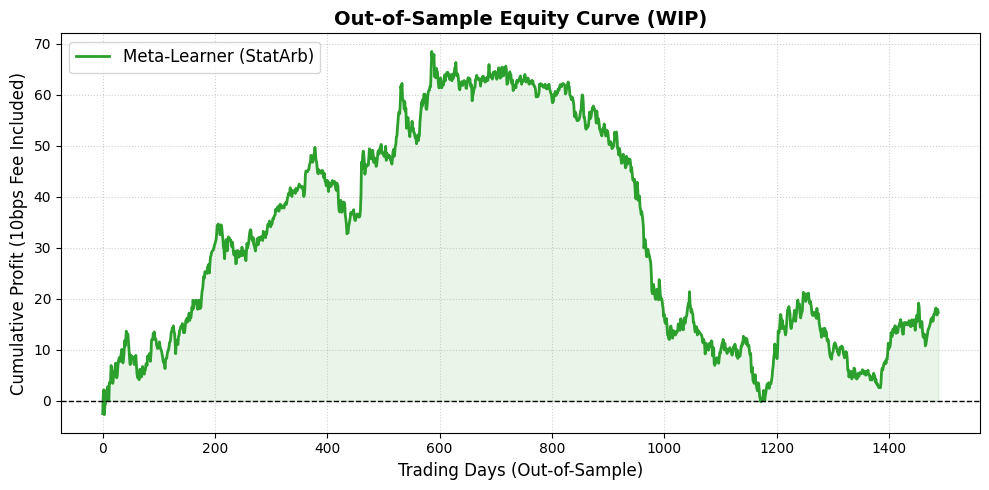

In [31]:
if __name__ == "__main__":
    OHLCV_PATH = '../../data/consolidated_daily_ohlcv.parquet'
    RETURNS_PATH = '../../data/consolidated_daily_returns.parquet'
    execute_advanced_strategy(OHLCV_PATH, RETURNS_PATH)